# 临近光流外推

数据用 `D:\\data1\\zhongzhuan\\nimm_test_data\\multi_rain_mait24_blending\\test_data\\ecmwf\\sfc\\20260521` 的 ECMWF 24 小时降水预报，Micaps4，起报 2026052100。预报时效 036、048、060 小时，间隔 12 小时。下面先裁出有降水且空间变化明显的区域，再依次做 Lucas–Kanade 估速、LsqrOpticalFlow、半拉格朗日外推、Lagrangian、S-PROG、LINDA 和 STEPS。预报时效 084 小时的场只用来对照，不参与估速。这三帧是相隔 12 小时的重叠 24 小时累计降水预报。


In [1]:
import contextlib
import io
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from scipy.ndimage import uniform_filter

ROOT = Path(r"d:\Work\NIMM_pip_repos\00temp")
PKG = ROOT / "optical_flow_nowcast"
for path in (ROOT, PKG):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

with contextlib.redirect_stdout(io.StringIO()):
    import meteva_base as meb

meteva = types.ModuleType("meteva")
meteva.base = meb
sys.modules["meteva"] = meteva
sys.modules["meteva.base"] = meb

from src.extrapolation_plugin import Extrapolation
from src.lagrangian_plugin import Lagrangian
from src.linda_plugin import Linda
from src.lk_plugin import LK
from src.lsqr_optical_flow_plugin import LsqrOpticalFlow
from src.sprog_plugin import Sprog
from src.steps_plugin import Steps

DATA_DIR = Path(
    r"D:\data1\zhongzhuan\nimm_test_data\multi_rain_mait24_blending\test_data\ecmwf\sfc\20260521"
)
CYCLE = pd.Timestamp("2026-05-21 00:00")
LEVELS = [0.1, 1, 5, 10, 25, 50, 100]
KM_PER_PIXEL = 11.0
TIMESTEP_MIN = 12 * 60

font = Path(r"C:\Windows\Fonts\msyh.ttc")
if font.is_file():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False


def load_lead(lead):
    path = DATA_DIR / f"2026052100.{lead:03d}.m4"
    grid = meb.read_griddata_from_micaps4(str(path))
    return grid.assign_coords(time=[CYCLE + pd.Timedelta(hours=lead)])


def rainy_window(field, nlat=140, nlon=180):
    smooth = uniform_filter(np.nan_to_num(field, nan=0.0), size=21)
    gy, gx = np.gradient(smooth)
    score = smooth * (np.hypot(gy, gx) + 0.02)
    iy, ix = np.unravel_index(int(np.nanargmax(score)), score.shape)
    y0 = int(np.clip(iy - nlat // 2, 0, field.shape[0] - nlat))
    x0 = int(np.clip(ix - nlon // 2, 0, field.shape[1] - nlon))
    return y0, y0 + nlat, x0, x0 + nlon


def show_panels(panels, lon, lat, suptitle):
    fig, axes = plt.subplots(1, len(panels), figsize=(4.4 * len(panels), 4.6), constrained_layout=True)
    if len(panels) == 1:
        axes = [axes]
    mesh = None
    for ax, (data, title) in zip(axes, panels):
        mesh = ax.contourf(lon, lat, np.clip(data, 0, None), levels=LEVELS, cmap="YlGnBu", extend="max")
        ax.set_title(title)
        ax.set_xlabel("经度")
        ax.set_ylabel("纬度")
        ax.set_aspect("equal", adjustable="box")
    fig.colorbar(mesh, ax=axes, shrink=0.8, label="24h 降水量 (mm)")
    fig.suptitle(suptitle)
    plt.show()


def lead_frame(result, step, reduce="first"):
    values = np.squeeze(np.asarray(result.values))
    if values.ndim == 2:
        return values
    if values.ndim == 3:
        return values[step]
    if reduce == "mean":
        return values.mean(axis=0)[step]
    return values[0, step]


fields = [load_lead(lead) for lead in (36, 48, 60)]
verify = load_lead(84)
y0, y1, x0, x1 = rainy_window(fields[-1].values.squeeze())
fields = [item.isel(lat=slice(y0, y1), lon=slice(x0, x1)) for item in fields]
verify = verify.isel(lat=slice(y0, y1), lon=slice(x0, x1))
lon = fields[-1].lon.values
lat = fields[-1].lat.values
print("crop lat", float(lat[0]), float(lat[-1]))
print("crop lon", float(lon[0]), float(lon[-1]))
print("input max", [float(np.nanmax(item.values)) for item in fields])
print("verify 084 max", float(np.nanmax(verify.values)))


crop lat 19.200000000000003 33.1
crop lon 120.0 137.9
input max [58.810001373291016, 82.37999725341797, 91.54000091552734]
verify 084 max 85.56999969482422


## Lucas–Kanade 估速

**原理。** 在时间连续的降水场上检测特征点，用 Lucas–Kanade 估计特征点在相邻时次之间的位移，再将稀疏运动矢量插值为稠密的 u、v。估速前可对降水做强度变换，减弱强降水对光流估计的影响。特征检测默认 Shi–Tomasi，插值默认反距离权重。插值前可用形态学开运算滤除孤立回波，按标准差剔除离群矢量，并对邻近矢量抽稀。

**参数。** 本示例传入三帧预报。`transform_method="box"`，`threshold=0.01` mm，`Lambda=0.3`。其余用预设：`fd_method=shitomasi`，`interp_method=idwinterp2d`，`dense=true`，离群剔除 `nr_std_outlier=3`、近邻 `k_outlier=30`，开运算核 `size_opening=3`，抽稀尺度 `decl_scale=20`。返回的时间间隔应是 12 小时。矢量画在预报时效 060 小时的场上，单位是格点/12h。


delta 12:00:00
speed p50/p95/max 3.7092723846435547 7.741715908050537 11.191010475158691


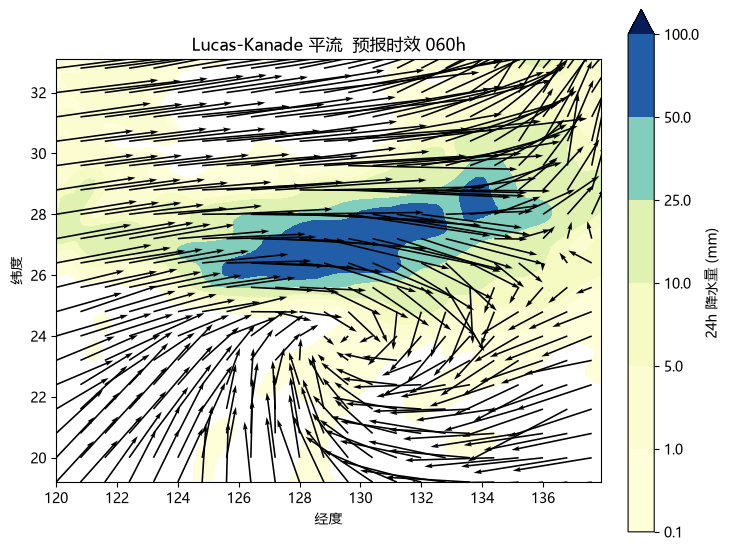

In [2]:
uv, delta = LK(
    transform_method="box",
    transform_para={"threshold": 0.01, "Lambda": 0.3},
).process(fields)
speed = np.hypot(uv.values[0].squeeze(), uv.values[1].squeeze())
print("delta", delta)
print(
    "speed p50/p95/max",
    float(np.nanpercentile(speed, 50)),
    float(np.nanpercentile(speed, 95)),
    float(np.nanmax(speed)),
)

fig, ax = plt.subplots(figsize=(7.2, 5.4), constrained_layout=True)
mesh = ax.contourf(
    lon, lat, np.clip(fields[-1].values.squeeze(), 0, None),
    levels=LEVELS, cmap="YlGnBu", extend="max",
)
step = 8
ax.quiver(
    lon[::step], lat[::step],
    uv.values[0].squeeze()[::step, ::step],
    uv.values[1].squeeze()[::step, ::step],
    color="k", angles="xy", scale_units="xy", scale=1.5,
)
ax.set_title("Lucas-Kanade 平流  预报时效 060h")
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
ax.set_aspect("equal", adjustable="box")
fig.colorbar(mesh, ax=ax, label="24h 降水量 (mm)")
plt.show()


## LsqrOpticalFlow

**原理。** 在前一时次与后一时次降水场上设置滑动窗口。窗口内降水达到阈值、前后变差达到阈值且有效格点不少于下限时，用带阻尼的最小二乘估计该窗口的平流速度。窗口尺度以经纬度给出。稀疏速度再经 Cressman 插值到整场，得到 u、v，单位是度/步，与经纬度一致。

**参数。** 前一场是预报时效 048 小时，后一场是 060 小时。`min_window=[[5.0, 5.0]]`，经向、纬向各 5°。`rain_limit=0.1` mm，`delta_rain_limit=0.1` mm，`num_limit=100`，`lsqr_damp=0.01`，都是预设。类名也可写为 `OpticalFlow`、`WindowLsqr`。矢量长度就是 12 小时的经纬度位移，只画降水量不低于 1 mm 的格点。


delta 12:00:00
speed deg p50/p95/max 0.22705546021461487 0.9498569965362549 1.15386164188385


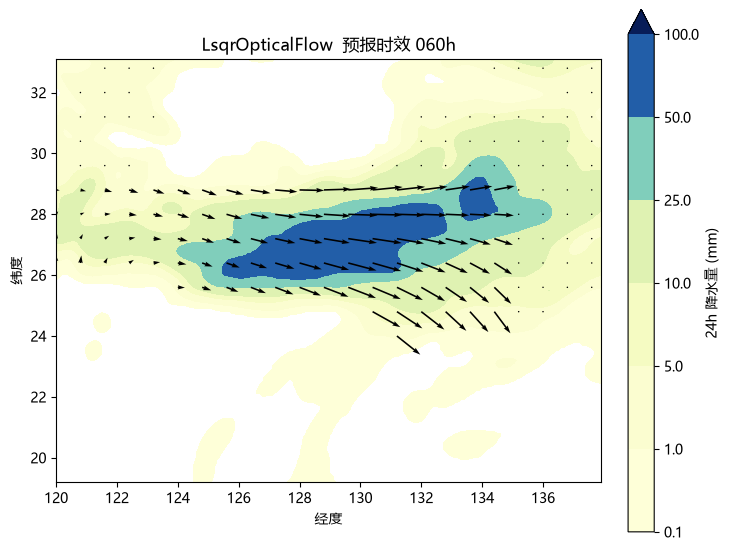

In [3]:

uv_lsqr, delta_lsqr = LsqrOpticalFlow(min_window=[[5.0, 5.0]]).process(fields[-2], fields[-1])
speed_lsqr = np.hypot(uv_lsqr.values[0].squeeze(), uv_lsqr.values[1].squeeze())
print("delta", delta_lsqr)
print(
    "speed deg p50/p95/max",
    float(np.nanpercentile(speed_lsqr, 50)),
    float(np.nanpercentile(speed_lsqr, 95)),
    float(np.nanmax(speed_lsqr)),
)

rain060 = np.clip(fields[-1].values.squeeze(), 0, None)
show_u = uv_lsqr.values[0].squeeze().astype(float).copy()
show_v = uv_lsqr.values[1].squeeze().astype(float).copy()
show_u[rain060 < 1] = np.nan
show_v[rain060 < 1] = np.nan
fig, ax = plt.subplots(figsize=(7.2, 5.4), constrained_layout=True)
mesh = ax.contourf(lon, lat, rain060, levels=LEVELS, cmap="YlGnBu", extend="max")
step = 8
ax.quiver(
    lon[::step], lat[::step],
    show_u[::step, ::step], show_v[::step, ::step],
    color="k", angles="xy", scale_units="xy", scale=1,
)
ax.set_title("LsqrOpticalFlow  预报时效 060h")
ax.set_xlabel("经度")
ax.set_ylabel("纬度")
ax.set_aspect("equal", adjustable="box")
fig.colorbar(mesh, ax=ax, label="24h 降水量 (mm)")
plt.show()


## 半拉格朗日外推

**原理。** 速度场给出每个格点在一个时间步内的位移。外推沿该位移回溯上游位置，从最近一张降水场取值，并按步数逐步积分。默认方案是 `semilagrangian`。本节用的是上一节 Lucas–Kanade 的格点位移。

**参数。** `timesteps=2`。`delta_t` 用估速返回的 12 小时，不用命令行预设的 `delta_min=10` 分钟。`extrap_method` 保持 `semilagrangian`。最右侧是同一裁剪范围的预报时效 084 小时，不参与计算。


extrapolation

 (1, 1, 1, 2, 140, 180) 0.0 91.38333892822266


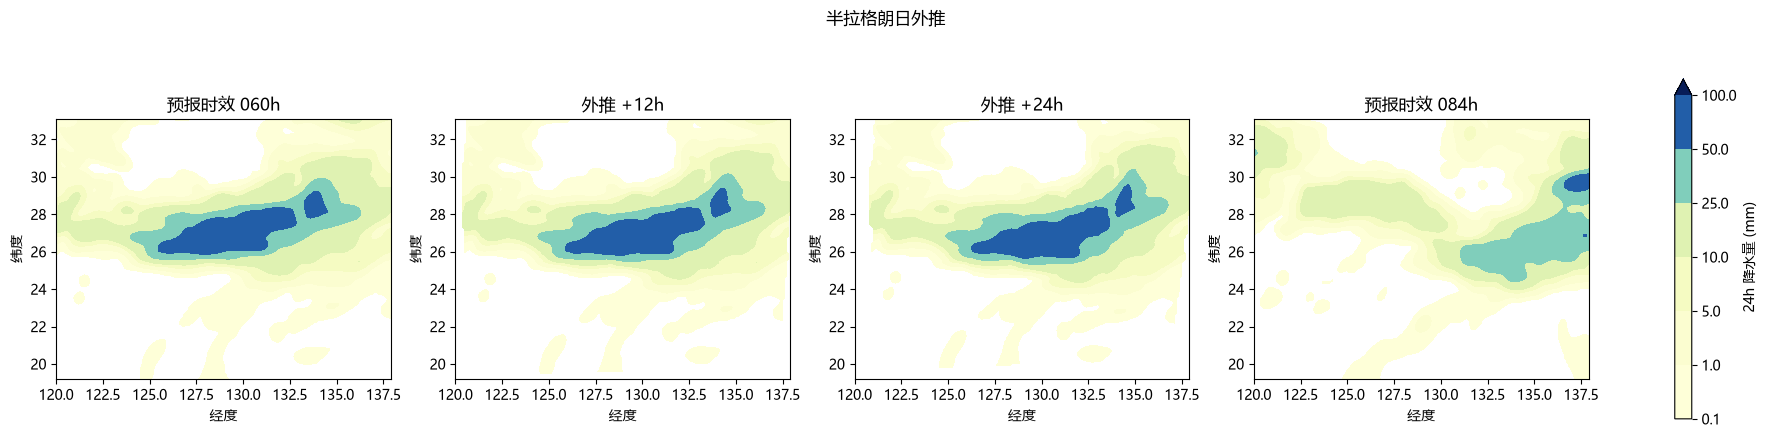

In [4]:
extra = Extrapolation().process(fields, uv, timesteps=2, delta_t=delta)
print("extrapolation", extra.shape, float(np.nanmin(extra.values)), float(np.nanmax(extra.values)))
show_panels(
    [
        (fields[-1].values.squeeze(), "预报时效 060h"),
        (lead_frame(extra, 0), "外推 +12h"),
        (lead_frame(extra, 1), "外推 +24h"),
        (verify.values.squeeze(), "预报时效 084h"),
    ],
    lon, lat, "半拉格朗日外推",
)


## Lagrangian

**原理。** 由 u、v 和 `delta_time` 计算各格点上游的经纬度，再对原降水场做双线性插值，得到平流一个时间步后的降水场。u、v 与经纬度使用同一单位。LsqrOpticalFlow 给出的是度/步，可以直接用；Lucas–Kanade 给出的是格点位移，不能直接当作经纬度增量。

**参数。** `u`、`v` 取上一节的速度场，`rain` 为预报时效 060 小时。`delta_time=1` 平流一个时次（12 小时），再用同一速度平流第二步。没有命令行，只在 Python 里调用。右侧预报时效 084 小时只作对照。


lagrangian +12h -0.011826229845261427 91.36579773630052
lagrangian +24h -0.17024049670900546 91.22928404900763


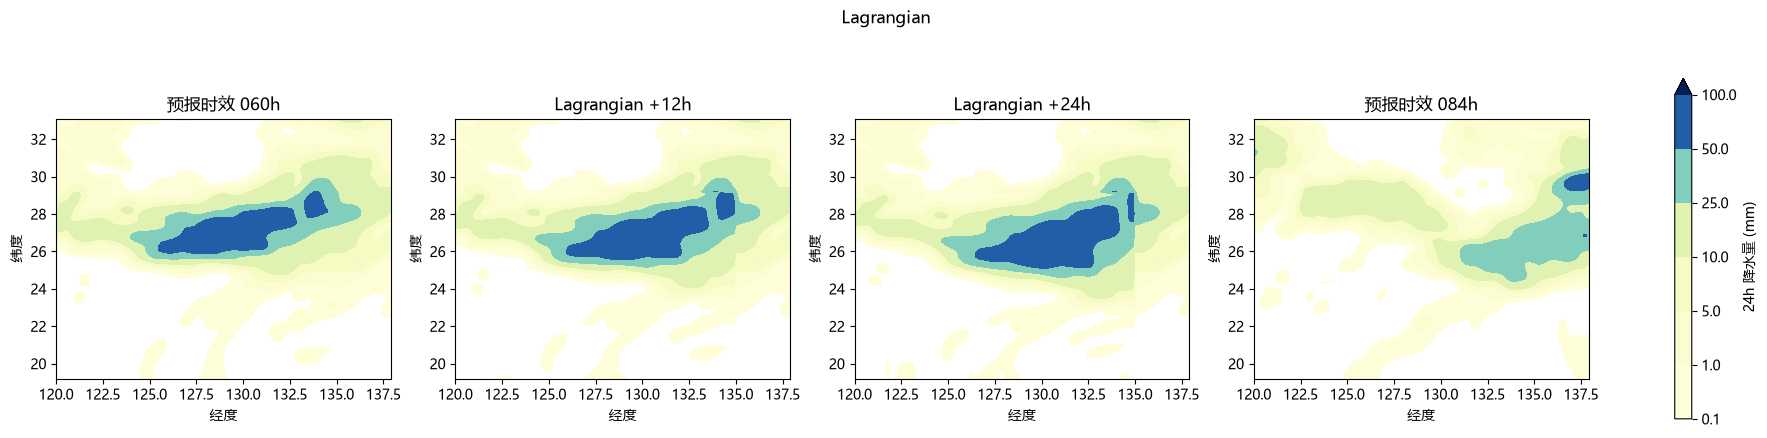

In [5]:
rain = fields[-1]
u = rain.copy()
v = rain.copy()
u.values = np.squeeze(uv_lsqr.values[0]).reshape(rain.values.shape)
v.values = np.squeeze(uv_lsqr.values[1]).reshape(rain.values.shape)
lag1 = Lagrangian().process(u, v, rain, delta_time=1.0)
lag2 = Lagrangian().process(u, v, lag1, delta_time=1.0)
print("lagrangian +12h", float(np.nanmin(lag1.values)), float(np.nanmax(lag1.values)))
print("lagrangian +24h", float(np.nanmin(lag2.values)), float(np.nanmax(lag2.values)))
show_panels(
    [
        (rain.values.squeeze(), "预报时效 060h"),
        (np.squeeze(lag1.values), "Lagrangian +12h"),
        (np.squeeze(lag2.values), "Lagrangian +24h"),
        (verify.values.squeeze(), "预报时效 084h"),
    ],
    lon, lat, "Lagrangian",
)


## S-PROG

**原理。** 将降水场分解为若干空间尺度。各尺度用自回归分别演变后，再做半拉格朗日平流并叠加。随后用概率匹配，使预报降水的强度分布与最近时次一致。小尺度分量的可预报时效较短，随预报时效衰减。

**参数。** 三帧满足默认 `ar_order=2` 所需的输入长度。降水单位是毫米，`precip_thr=0.1`（代码预设 -5，面向反射率，这里改成毫米阈值）。`timesteps=2`，`delta_t` 为 12 小时。尺度层数预设 `n_cascade_levels=6`，分解 `fft`，带通 `gaussian`，概率匹配 `cdf`。速度用 Lucas–Kanade，本节不重新估速。


Computing S-PROG nowcast
------------------------

Inputs
------
input dimensions: 140x180

Methods
-------
extrapolation:          semilagrangian
bandpass filter:        gaussian
decomposition:          fft
conditional statistics: no
probability matching:   cdf
FFT method:             numpy
domain:                 spatial

Parameters
----------
number of time steps:     2
parallel threads:         1
number of cascade levels: 6
order of the AR(p) model: 2
precip. intensity threshold: 0.1
************************************************
* Correlation coefficients for cascade levels: *
************************************************
-----------------------------------------
| Level |     Lag-1     |     Lag-2     |
-----------------------------------------
| 1     | 0.921840      | 0.860935      |
-----------------------------------------
| 2     | 0.892466      | 0.693433      |
-----------------------------------------
| 3     | 0.421643      | 0.038630      |
------------------------

done.
Computing nowcast for time step 2... 

done.
sprog (1, 1, 1, 2, 140, 180) 0.0 91.31430053710938


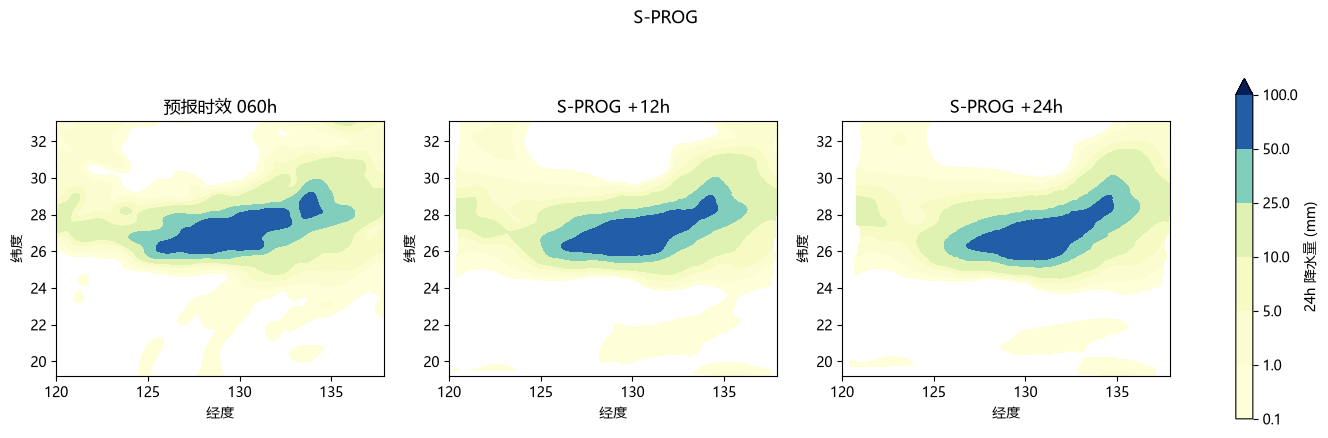

In [6]:
sprog = Sprog(precip_thr=0.1).process(fields, uv, timesteps=2, delta_t=delta)
print("sprog", sprog.shape, float(np.nanmin(sprog.values)), float(np.nanmax(sprog.values)))
show_panels(
    [
        (fields[-1].values.squeeze(), "预报时效 060h"),
        (lead_frame(sprog, 0), "S-PROG +12h"),
        (lead_frame(sprog, 1), "S-PROG +24h"),
    ],
    lon, lat, "S-PROG",
)


## LINDA

**原理。** 在降水场上检测局地特征，默认 blob 检测。用拉格朗日积分–差分方程和自回归描述特征的平流与生消，再按速度场外推。`add_perturbations` 为真时，对特征和速度加入扰动，生成集合成员。

**参数。** 本示例保持 `add_perturbations=false`，输出单一预报。`kmperpixel=11`，`timestep=720` 分钟，对应约 0.1° 和 12 小时，供速度扰动项使用。`seed=1`。特征数上限预设 25，`ari_order=1`，核类型 `anisotropic`。外推两步，速度用 Lucas–Kanade。


Computing LINDA nowcast
-----------------------

Inputs
------
dimensions:           140x180
number of time steps: 3

Methods
-------
nowcast type:         deterministic
feature detector:     blob
extrapolator:         semilagrangian
kernel type:          anisotropic

Parameters
----------
number of time steps:       2
ARI model order:            1
localization window radius: 28.0

Detecting features... 

found 25 blobs.
Transforming to Lagrangian coordinates... 

done.
Estimating the first convolution kernel... 

done.


Estimating the ARI(p,1) parameters... 

done.
Estimating the second convolution kernel... 

done.


Computing nowcast for time step 1... 

done.
Computing nowcast for time step 2... 

done.
linda (1, 1, 1, 2, 140, 180) 0.0 82.61257934570312


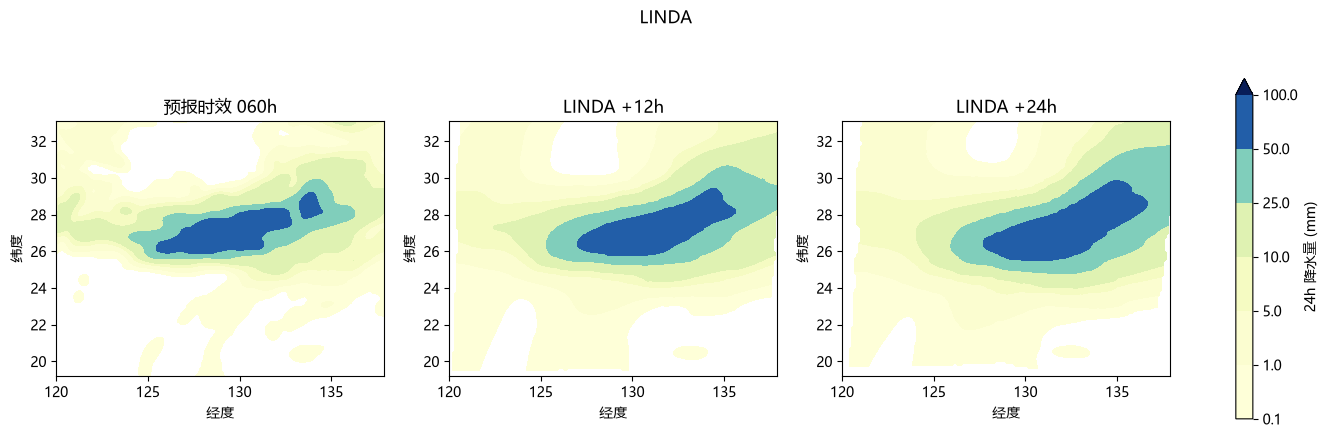

In [7]:
linda = Linda(kmperpixel=KM_PER_PIXEL, timestep=TIMESTEP_MIN, seed=1).process(
    fields, uv, timesteps=2, delta_t=delta
)
print("linda", linda.shape, float(np.nanmin(linda.values)), float(np.nanmax(linda.values)))
show_panels(
    [
        (fields[-1].values.squeeze(), "预报时效 060h"),
        (lead_frame(linda, 0), "LINDA +12h"),
        (lead_frame(linda, 1), "LINDA +24h"),
    ],
    lon, lat, "LINDA",
)


## STEPS

**原理。** 将降水场分解为若干空间尺度，各尺度分别演变并做半拉格朗日平流。同时对降水加入随机噪声、对平流加入扰动，得到多个集合成员。成员差异来自这些扰动。概率匹配使预报降水的强度分布与最近时次一致。

**参数。** `n_ens_members=4`（预设），`precip_thr=0.1`，`kmperpixel=11`，`timestep=720`，`seed=1`。外推两步。尺度层数预设 6，噪声方法 `nonparametric`，概率匹配 `cdf`，`vel_pert_method` 预设为不扰动速度。图给出成员 0 和集合平均。速度用 Lucas–Kanade，本入口不重新估速。


Computing STEPS nowcast
-----------------------

Inputs
------
input dimensions: 140x180
km/pixel:         11.0
time step:        720 minutes

Methods
-------
extrapolation:          semilagrangian
bandpass filter:        gaussian
decomposition:          fft
noise generator:        nonparametric
noise adjustment:       no
velocity perturbator:   None
conditional statistics: no
precip. mask method:    None
probability matching:   cdf
FFT method:             numpy
domain:                 spatial

Parameters
----------
number of time steps:     2
ensemble size:            4
parallel threads:         1
number of cascade levels: 6
order of the AR(p) model: 2
precip. intensity threshold: 0.1
************************************************
* Correlation coefficients for cascade levels: *
************************************************
-----------------------------------------
| Level |     Lag-1     |     Lag-2     |
-----------------------------------------
| 1     | 0.921840      | 0.8609

done.
Computing nowcast for time step 2... 

done.
steps (4, 1, 1, 2, 140, 180) 0.0 91.49832153320312


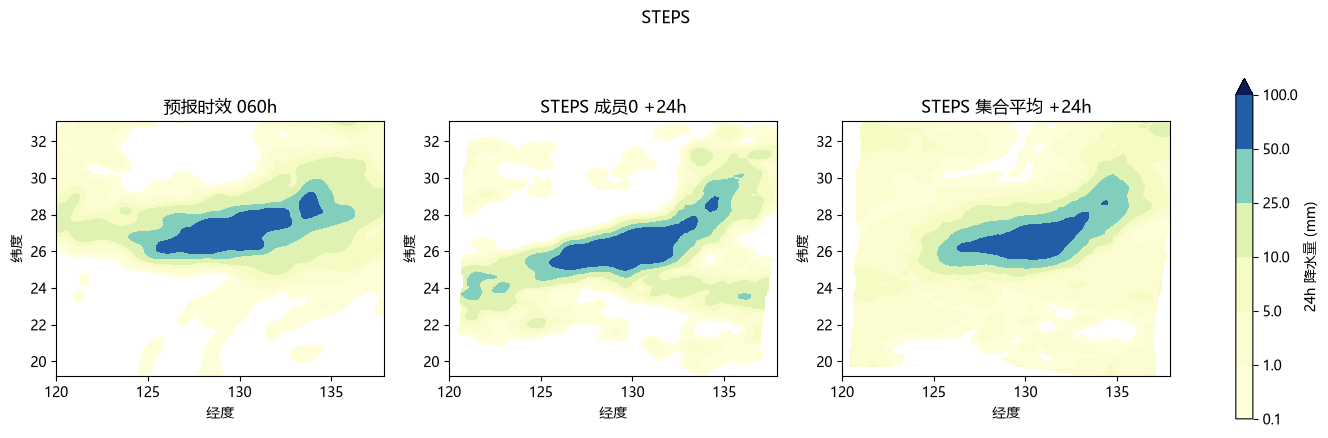

In [8]:
steps = Steps(
    precip_thr=0.1,
    kmperpixel=KM_PER_PIXEL,
    timestep=TIMESTEP_MIN,
    n_ens_members=4,
    seed=1,
).process(fields, uv, timesteps=2, delta_t=delta)
print("steps", steps.shape, float(np.nanmin(steps.values)), float(np.nanmax(steps.values)))
show_panels(
    [
        (fields[-1].values.squeeze(), "预报时效 060h"),
        (lead_frame(steps, 1, reduce="first"), "STEPS 成员0 +24h"),
        (lead_frame(steps, 1, reduce="mean"), "STEPS 集合平均 +24h"),
    ],
    lon, lat, "STEPS",
)
